**Understanding Hospital Resource Allocation and Patient Needs**

Problem statement:

Analyze the data to optimize hospital operations and enhance patient care by analyzing patient admissions data to identify patterns in admission types, illness severities, ward distribution, and hospital utilization, thereby providing actionable insights for targeted resource allocation, efficient care delivery, and overall operational efficiency improvement.


```
Column.................Description
case_id................Case_ID registered in Hospital
Hospital_code..........Unique code for the Hospital
Hospital_type_code.....Unique code for the type of Hospital
City_Code_Hospital.....City Code of the Hospital
Hospital_region_code...Region Code of the Hospital
Available Extra Rooms in Hospital...Number of Extra rooms available in the Hospital
Department.............Department overlooking the case Ward_Type
Ward_Type..............Code for the Ward type
Ward_Facility_Code.....Code for the Ward Facility
Bed Grade..............Condition of Bed in the Ward
patientid..............Unique Patient Id
City_Code_Patient......City Code for the patient
Type of Admission......Admission Type registered by the Hospital
Severity of Illness....Severity of the illness recorded at the time of admission
Visitors with Patient.Number of Visitors with the patient
Age...................Age of the patient
Admission_Deposit.....Deposit at the Admission Time
Stay..................Stay Days by the patient
,
```


In [ ]:
# importing libraries for our purpose

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as snss

In [ ]:
# loading the data
df=pd.read_csv("Hospital_Data.csv")

In [ ]:
df.head()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50


In [ ]:
# length of data
len(df)

318438

In [ ]:
# checking data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available Extra Rooms in Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed Grade                          318325 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3139

In [ ]:
# checking for null values
df.isnull().sum()

case_id                                 0
Hospital_code                           0
Hospital_type_code                      0
City_Code_Hospital                      0
Hospital_region_code                    0
Available Extra Rooms in Hospital       0
Department                              0
Ward_Type                               0
Ward_Facility_Code                      0
Bed Grade                             113
patientid                               0
City_Code_Patient                    4532
Type of Admission                       0
Severity of Illness                     0
Visitors with Patient                   0
Age                                     0
Admission_Deposit                       0
Stay                                    0
dtype: int64

There are null values present in bed grade and City_Code_Patient:

Bed Grade null values are going to treated with mode, where as City_Code_Patient with "unknown"

In [ ]:
# Fill null values in 'Bed Grade' with mode
mode = df['Bed Grade'].mode()[0]
df['Bed Grade'] = df['Bed Grade'].fillna(mode)

# Fill null values in 'City_Code_Patient' with 'unknown'
df['City_Code_Patient'] = df['City_Code_Patient'].fillna('unknown')


In [ ]:
# Re-checking for null values
df.isnull().sum()

case_id                              0
Hospital_code                        0
Hospital_type_code                   0
City_Code_Hospital                   0
Hospital_region_code                 0
Available Extra Rooms in Hospital    0
Department                           0
Ward_Type                            0
Ward_Facility_Code                   0
Bed Grade                            0
patientid                            0
City_Code_Patient                    0
Type of Admission                    0
Severity of Illness                  0
Visitors with Patient                0
Age                                  0
Admission_Deposit                    0
Stay                                 0
dtype: int64

In [ ]:
# looking into unique values of the data
df.nunique()

case_id                              318438
Hospital_code                            32
Hospital_type_code                        7
City_Code_Hospital                       11
Hospital_region_code                      3
Available Extra Rooms in Hospital        18
Department                                5
Ward_Type                                 6
Ward_Facility_Code                        6
Bed Grade                                 4
patientid                             92017
City_Code_Patient                        37
Type of Admission                         3
Severity of Illness                       3
Visitors with Patient                    28
Age                                      10
Admission_Deposit                      7300
Stay                                     11
dtype: int64

The data given is about 92017 patients in 32 hospital present in 3 region

In [ ]:
df.columns

Index(['case_id', 'Hospital_code', 'Hospital_type_code', 'City_Code_Hospital',
       'Hospital_region_code', 'Available Extra Rooms in Hospital',
       'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed Grade',
       'patientid', 'City_Code_Patient', 'Type of Admission',
       'Severity of Illness', 'Visitors with Patient', 'Age',
       'Admission_Deposit', 'Stay'],
      dtype='object')

In [ ]:
# cheking unique values to find any abnormal data
for i in df.columns:
  print (i,"  ", df[i].unique())
  print (25*"_ _")

case_id    [     1      2      3 ... 318436 318437 318438]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Hospital_code    [ 8  2 10 26 23 32  1 22 16  9  6 29 12  3 21 28 27 19  5 14 13 31 24 17
 25 15 11 30 18  4  7 20]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Hospital_type_code    ['c' 'e' 'b' 'a' 'f' 'd' 'g']
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
City_Code_Hospital    [ 3  5  1  2  6  9 10  4 11  7 13]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Hospital_region_code    ['Z' 'X' 'Y']
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Available Extra Rooms in Hospital    [ 3  2  1  4  6  5  7  8  9 10 12  0 11 20 14 21 13 24]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Department    ['radiotherapy' 'anesthesia' 'gynecology' 'TB & Chest disease' 'surgery']
_ __ __ __ __ __ __ __ __ __ __ __ __ __ 

From the data it is observed that, in the columns of Age and Stay Nov-20 is entered instead of 11-20 bin.

In [ ]:
# Replace 'Nov' with '11' in 'Age' and 'Stay'
df['Age'] = df['Age'].replace('Nov-20', '11-20')
df["Stay"]=df["Stay"].replace("Nov-20", "11-20")

In [ ]:
# re-cheking unique values
for i in df.columns:
  print (i,"  ", df[i].unique())
  print (25*"_ _")

case_id    [     1      2      3 ... 318436 318437 318438]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Hospital_code    [ 8  2 10 26 23 32  1 22 16  9  6 29 12  3 21 28 27 19  5 14 13 31 24 17
 25 15 11 30 18  4  7 20]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Hospital_type_code    ['c' 'e' 'b' 'a' 'f' 'd' 'g']
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
City_Code_Hospital    [ 3  5  1  2  6  9 10  4 11  7 13]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Hospital_region_code    ['Z' 'X' 'Y']
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Available Extra Rooms in Hospital    [ 3  2  1  4  6  5  7  8  9 10 12  0 11 20 14 21 13 24]
_ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ __ _
Department    ['radiotherapy' 'anesthesia' 'gynecology' 'TB & Chest disease' 'surgery']
_ __ __ __ __ __ __ __ __ __ __ __ __ __ 

In [ ]:
# statistical analysis
df.describe()

,case_id,Hospital_code,City_Code_Hospital,Available Extra Rooms in Hospital,Bed Grade,patientid,Visitors with Patient,Admission_Deposit
count,318438.000000,318438.000000,318438.000000,318438.000000,318438.000000,318438.000000,318438.000000,318438.000000
mean,159219.500000,18.318841,4.771717,3.197627,2.625585,65747.579472,3.284099,4880.749392
std,91925.276848,8.633755,3.102535,1.168171,0.873070,37979.936440,1.764061,1086.776254
min,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1800.000000
25%,79610.250000,11.000000,2.000000,2.000000,2.000000,32847.000000,2.000000,4186.000000
50%,159219.500000,19.000000,5.000000,3.000000,3.000000,65724.500000,3.000000,4741.000000
75%,238828.750000,26.000000,7.000000,4.000000,3.000000,98470.000000,4.000000,5409.000000
max,318438.000000,32.000000,13.000000,24.000000,4.000000,131624.000000,32.000000,11008.000000


In [ ]:
# categorical analysis
df.describe(include='O')


,Hospital_type_code,Hospital_region_code,Department,Ward_Type,Ward_Facility_Code,City_Code_Patient,Type of Admission,Severity of Illness,Age,Stay
count,318438,318438,318438,318438,318438,318438.0,318438,318438,318438,318438
unique,7,3,5,6,6,38.0,3,3,10,11
top,a,X,gynecology,R,F,8.0,Trauma,Moderate,41-50,21-30
freq,143425,133336,249486,127947,112753,124011.0,152261,175843,63749,87491


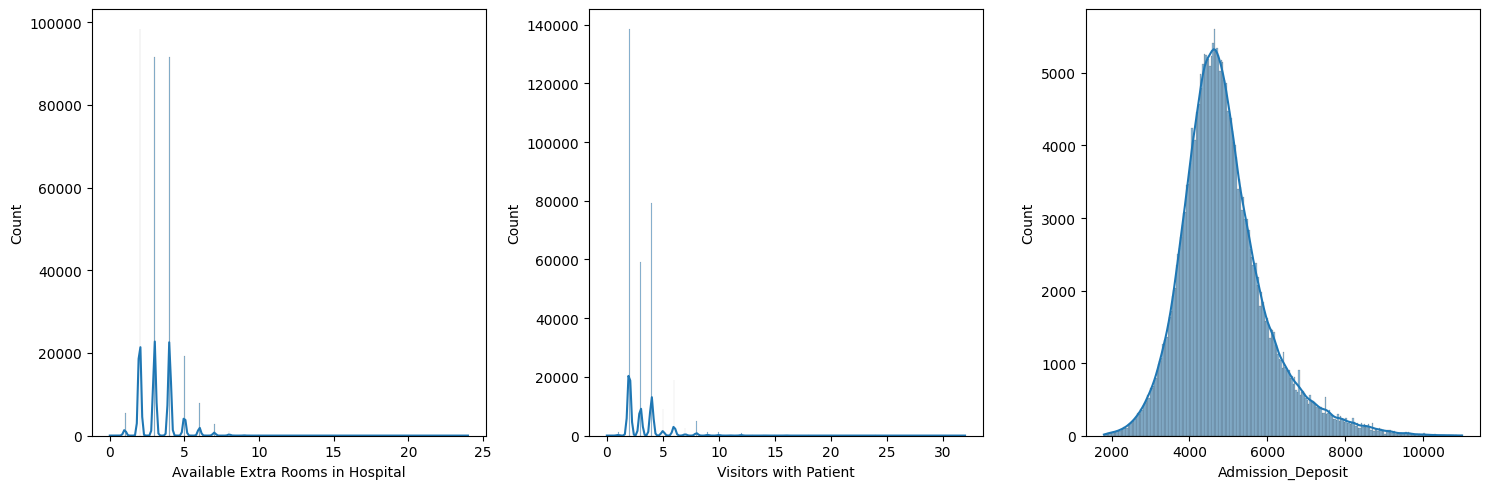

In [ ]:
# Univariate Analysis
numerical_features = ['Available Extra Rooms in Hospital', 'Visitors with Patient', 'Admission_Deposit']
fig, axes = plt.subplots(nrows=1, ncols=len(numerical_features), figsize=(15, 5))
for i, feature in enumerate(numerical_features):
    snss.histplot(data=df, x=feature, ax=axes[i], kde=True)
plt.tight_layout()
plt.show()

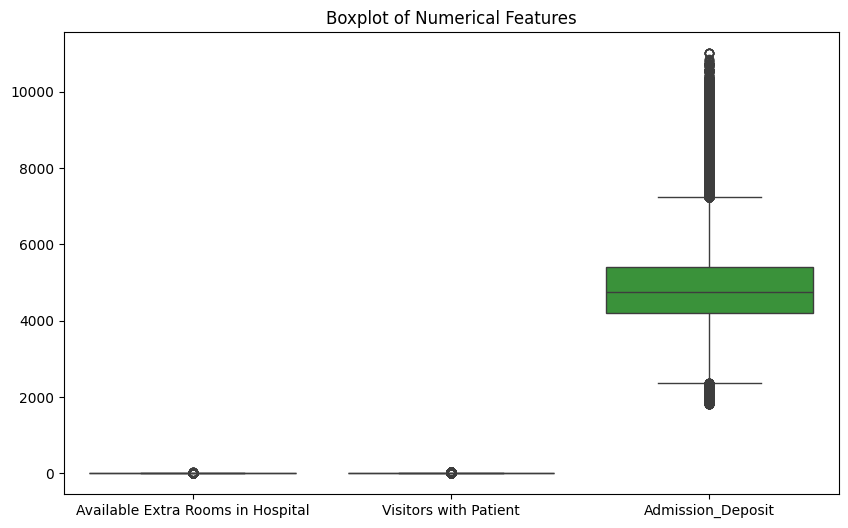

In [ ]:
# Boxplot
plt.figure(figsize=(10, 6))
snss.boxplot(data=df[numerical_features])
plt.title('Boxplot of Numerical Features')
plt.show()


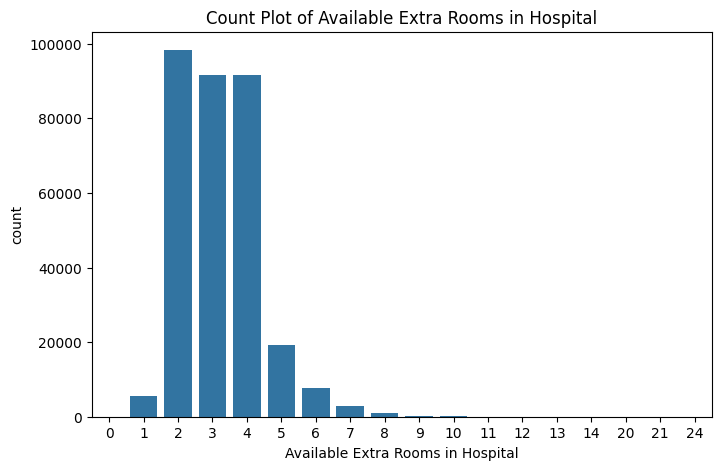

In [ ]:
# Count Plot (for discrete numerical features)
count_features = ['Available Extra Rooms in Hospital']
plt.figure(figsize=(8, 5))
for feature in count_features:
    snss.countplot(data=df, x=feature)
plt.title('Count Plot of Available Extra Rooms in Hospital')
plt.show()

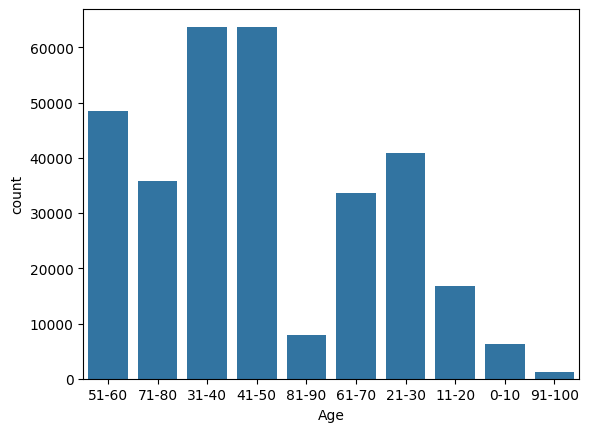

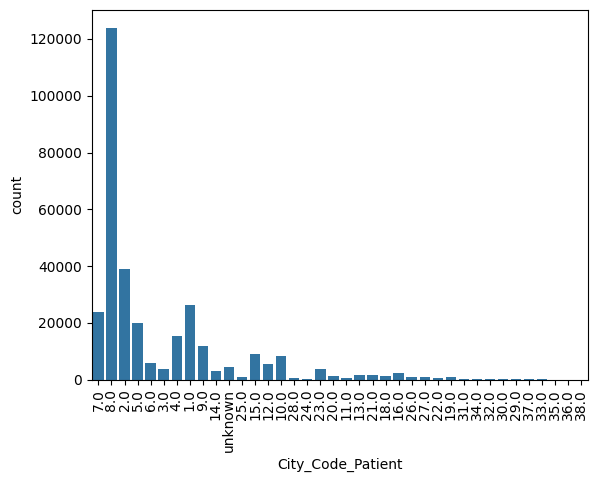

In [ ]:
# Explore Patient Demographics
snss.countplot(data=df, x='Age')
plt.show()

snss.countplot(data=df, x='City_Code_Patient')
plt.xticks(rotation=90)
plt.show()


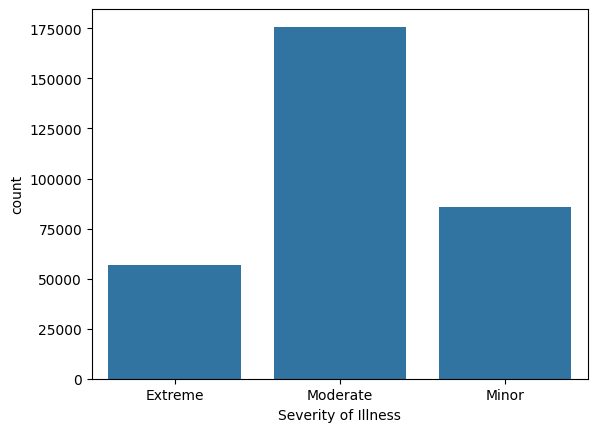

In [ ]:
# Analyze Illness Severity
snss.countplot(data=df, x='Severity of Illness')
plt.show()

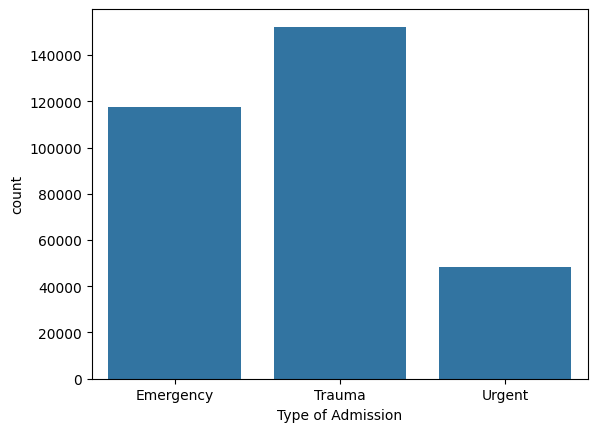

In [ ]:
# Admission Types Analysis
snss.countplot(data=df, x='Type of Admission')
plt.show()

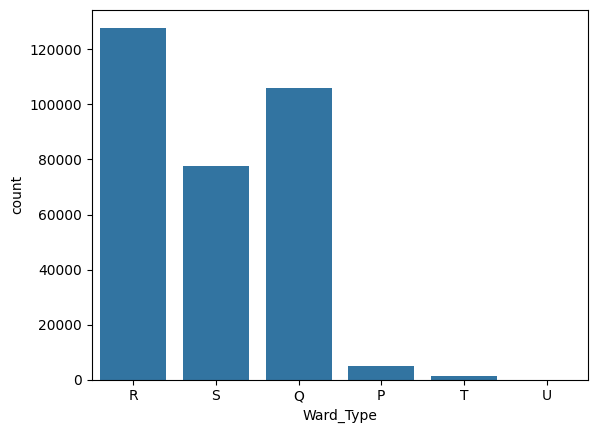

In [ ]:
# Admission Types Analysis
snss.countplot(data=df, x='Ward_Type')
plt.show()

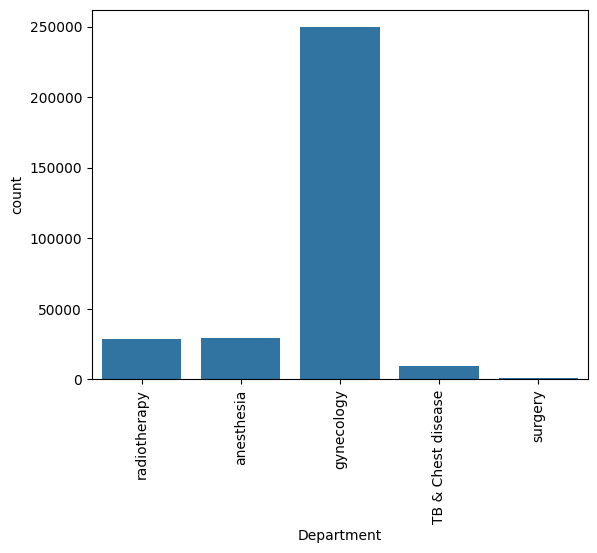

In [ ]:
# Department type  Analysis
snss.countplot(data=df, x='Department')
plt.xticks(rotation=90)
plt.show()

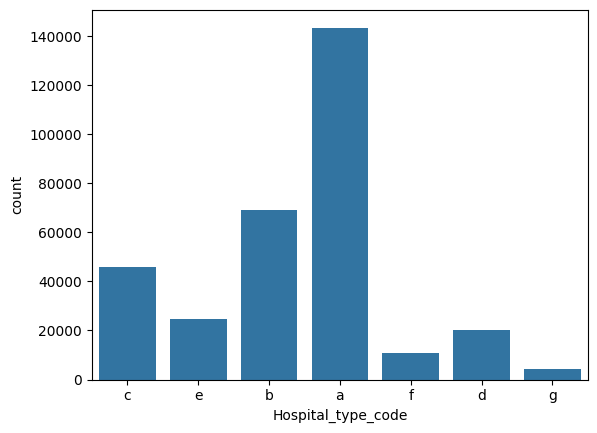

In [ ]:
# Hospital Utilization Assessment
snss.countplot(data=df, x='Hospital_type_code')
plt.show()

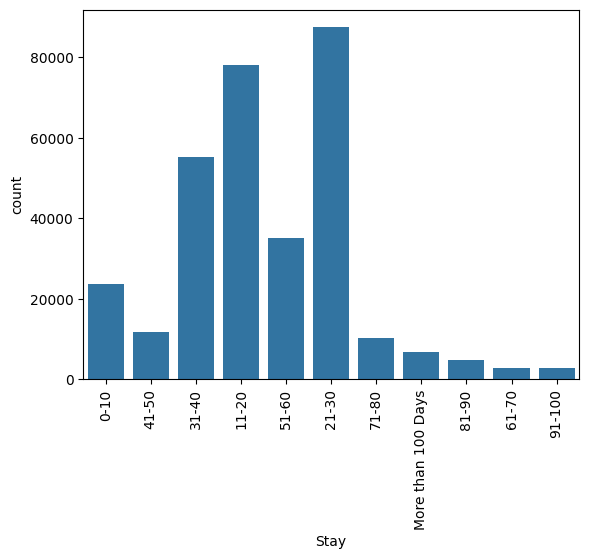

In [ ]:
# Hospital Stay Assessment
snss.countplot(data=df, x='Stay')
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Which region contains how many hospitals
region_hospital_count = df.groupby('Hospital_region_code')['Hospital_code'].nunique().reset_index()
print("Region-wise hospital count:")
print(region_hospital_count)

Region-wise hospital count:
  Hospital_region_code  Hospital_code
0                    X             12
1                    Y             10
2                    Z             10


In [ ]:
# Which department has the highest stay rate
department_stay_rate = df.groupby('Department')['Stay'].value_counts(normalize=True).unstack().fillna(0)
department_stay_rate['total_stay_rate'] = department_stay_rate.sum(axis=1)
highest_stay_department = department_stay_rate['total_stay_rate'].idxmax()
print("\nDepartment having the highest stay rate:")
print(highest_stay_department)


Department having the highest stay rate:
TB & Chest disease


**INSIGHTS AND RECOMENDATIONS**



Numerical Data:

-The 'Available Extra Rooms in Hospital' column has a mean of approximately 3.20 with a standard deviation of 1.17, indicating some variability in the number of extra rooms across hospitals.

-The 'Bed Grade' column has a mean of approximately 2.63 with a standard deviation of 0.87, suggesting that most hospitals have a bed grade of around 2 or 3.

-The 'Visitors with Patient' column has a mean of approximately 3.28 with a standard deviation of 1.76, indicating some variability in the number of visitors per patient.

-The 'Admission_Deposit' column has a mean of approximately 4880.75 with a standard deviation of 1086.78, indicating some variability in the admission deposits.


Categorical Data:


-The most common 'Hospital_type_code' is 'a', indicating that this type of hospital is most prevalent in the dataset.

-The most common 'Hospital_region_code' is 'X', indicating that hospitals in region X are most prevalent in the dataset.

-The most common 'Department' is 'gynecology', indicating that this department is the most common in the dataset.

-The most common 'Ward_Type' is 'R', indicating that this type of ward is most prevalent in the dataset.

-The most common 'Ward_Facility_Code' is 'F', indicating that this facility code is most prevalent in the dataset.

-The most common 'Type of Admission' is 'Trauma', indicating that this type of admission is most common in the dataset.

-The most common 'Severity of Illness' is 'Moderate', indicating that this severity level is most common in the dataset.

-The most common 'Age' group is '41-50', indicating that this age group is most common in the dataset.

-The most common 'Stay' category is '21-30', indicating that patients staying for 21-30 days are most common in the dataset.


Insights and Recommendations:

-Hospitals should consider increasing the number of extra rooms to accommodate more patients, especially during peak times.

-Hospitals should focus on improving the quality of beds and facilities to enhance patient comfort and satisfaction.

-Hospitals should manage visitor policies to ensure a balance between patient comfort and privacy.

-Hospitals should review their admission deposit policies to ensure they are competitive and fair.

